In [1]:
#!uv add causal-learn
#!uv add graphviz
#sudo apt-get update && sudo apt-get install -y graphviz

In [2]:
from aml_working_paper.config import INTERIM_DATA_DIR, RAW_DATA_DIR
from aml_working_paper.data.preprocess import preprocess_data
from aml_working_paper.routing.routing_investigate import select_investigations
from aml_working_paper.causal.local_sample import prepare_local_windows
from aml_working_paper.causal.discovery_data import prepare_discovery_data
from aml_working_paper.causal.discovery import discover_pc, discover_fci
from aml_working_paper.causal.ground_truth import get_ground_truth
from aml_working_paper.causal.evaluation import evaluate_skeleton, summarize_causal_results

import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import io
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from causallearn.utils.GraphUtils import GraphUtils

### 1. Load data, process it and define observable variables

In [3]:
routing_df = pd.read_parquet("{}/routing_df.parquet".format(INTERIM_DATA_DIR))
candidates = pd.read_parquet("{}/candidates.parquet".format(INTERIM_DATA_DIR))
df_aml = pd.read_csv("{}/synthetic_df_aml.csv".format(RAW_DATA_DIR))

In [4]:
train_df, val_df, test_df, train_sequences, val_sequences, test_sequences, scaler = preprocess_data(df_aml)

In [5]:
features = [ "economic_context", "account_exposure", "structuring_score", "cross_border_ratio", "transaction_volume"]

### 2. Use routing to select windows using uncertainty

In [6]:
selected = select_investigations(candidates, budget=10, strategy="uncertainty",)
local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)

In [7]:
selected.head()

,account_id,start_time,end_time,start_idx,end_idx,uncertainty,surprise,routing_score
0,55.0,18.0,27.0,18.0,27.0,0.634404,3.753619,0.634404
1,15.0,70.0,79.0,70.0,79.0,0.633793,3.955954,0.633793
2,30.0,30.0,39.0,30.0,39.0,0.633279,3.846830,0.633279
3,80.0,90.0,99.0,90.0,99.0,0.633250,3.741981,0.633250
4,53.0,79.0,88.0,79.0,88.0,0.631723,4.684777,0.631723


In [8]:
pd.DataFrame(local_windows[0]["data"])

,time,economic_context,account_exposure,structuring_score,cross_border_ratio,transaction_volume
18,18,-0.985434,0.061948,0.600674,0.311376,23.353993
19,19,-0.712667,0.074647,0.653479,0.340143,29.255242
20,20,-0.030768,0.205329,0.337485,0.255258,13.256029
21,21,-0.709335,0.080911,0.574244,0.112332,13.762872
22,22,-0.344557,0.047874,0.315098,0.187702,18.888078
23,23,0.358036,0.141916,0.765080,0.247261,26.361263
24,24,0.699606,0.081910,0.531208,0.605016,20.704120
25,25,0.790572,0.143995,0.486489,0.460297,22.683449
26,26,0.100495,0.102052,0.900002,0.322075,25.158210
27,27,-0.292715,0.271902,0.145264,0.126063,17.140852


#### 3. Check window 1 (0) and the behaviour of the observed values

In [9]:
window_0 = local_windows[0]["data"]
subplot_titles = ("Economic context", "Account Exposure", "Structuring Score", "Cross Border Ratio", "Transaction Volume")  # add titles for rows 3, 4, 5 if needed
fig = make_subplots(rows=5, cols=1, shared_xaxes=True, subplot_titles=subplot_titles)
traces_config = [(window_0["economic_context"], 1), (window_0["account_exposure"], 2), (window_0["structuring_score"], 3), (window_0["cross_border_ratio"], 4), (window_0["transaction_volume"], 5) ]

for column, col_num in traces_config:
  fig.add_trace(go.Scatter(x=window_0["time"], y=column, mode="lines"), row=col_num, col=1)

fig.update_layout(height=1200)
fig.show()

In [10]:
fig.write_html("/workspaces/aml-working-paper/reports/figures/observed_variables_behavior.html")

### 4. Check the ground truth

In [11]:
gt_edges, temporal_edges = get_ground_truth()

In [12]:
gt_edges

[('economic_context', 'account_exposure'),
 ('economic_context', 'transaction_volume'),
 ('account_exposure', 'aml_state'),
 ('account_exposure', 'cross_border_ratio'),
 ('aml_state', 'structuring_score'),
 ('aml_state', 'cross_border_ratio'),
 ('aml_state', 'transaction_volume'),
 ('structuring_score', 'transaction_volume')]

In [13]:
temporal_edges

[('economic_context', 'economic_context', 1), ('aml_state', 'aml_state', 1)]

In [14]:
print("Ground Truth edges:", len(gt_edges))
print("Temporal edges:", len(temporal_edges))

Ground Truth edges: 8
Temporal edges: 2


### 5. Combine windows for causal discovery

In [15]:
discovery_data = prepare_discovery_data(local_windows)
observations = discovery_data[features].to_numpy()

### 6. Apply PC and FCI on the discovery data

In [16]:
variable_names = {"X1": "economic_context", 
                  "X2": "account_exposure", 
                  "X3": "structuring_score", 
                  "X4": "cross_border_ratio", 
                  "X5": "transaction_volume"}

In [17]:
pc_graph = discover_pc(discovery_data, features, alpha=0.05)
fci_graph = discover_fci(discovery_data, features, alpha=0.05)

  0%|          | 0/5 [00:00<?, ?it/s]

#### PC

In [18]:
for edge in pc_graph.G.get_graph_edges():
    print(edge)

X1 --- X2
X1 --> X5
X3 --- X4
X3 --> X5
X4 --> X5


In [19]:
### save edges for metrics
pc_edges = []
for edge in pc_graph.G.get_graph_edges():
    edge_text = str(edge)
    for old_name, new_name in variable_names.items():
        edge_text = edge_text.replace(old_name, new_name)
    print(edge_text)
    pc_edges.append(edge_text)

economic_context --- account_exposure
economic_context --> transaction_volume
structuring_score --- cross_border_ratio
structuring_score --> transaction_volume
cross_border_ratio --> transaction_volume


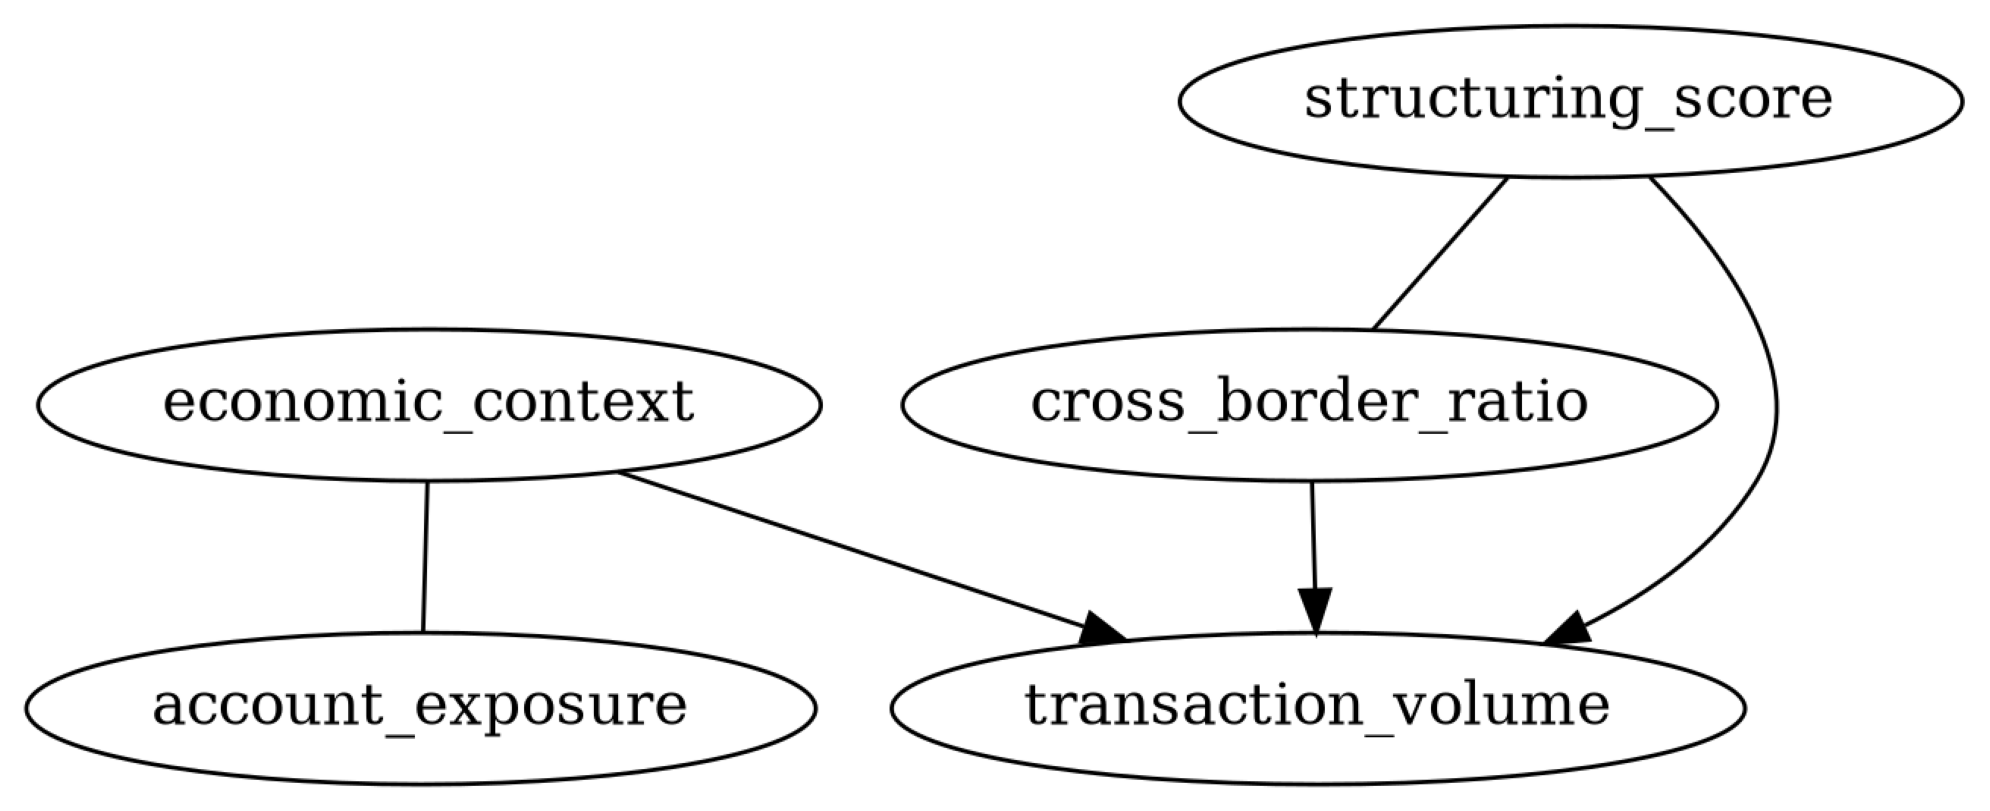

In [20]:
pc_graph.draw_pydot_graph(labels=features)

In [39]:
pd_graph = GraphUtils.to_pydot(pc_graph.G, labels=features)
pd_graph.write_png("/workspaces/aml-working-paper/reports/figures/pc_causal_graph.png")

#### FCI

In [22]:
for edge in fci_graph.get_graph_edges():
    print(edge)

X1 o-o X2
X1 o-> X5
X3 o-o X4
X3 o-> X5
X4 o-> X5


In [23]:
fci_edges = []
for edge in fci_graph.get_graph_edges():
    edge_text = str(edge)
    for old_name, new_name in variable_names.items():
        edge_text = edge_text.replace(old_name, new_name)
    print(edge_text)
    fci_edges.append(edge_text)

economic_context o-o account_exposure
economic_context o-> transaction_volume
structuring_score o-o cross_border_ratio
structuring_score o-> transaction_volume
cross_border_ratio o-> transaction_volume


In [24]:
gt_edges

[('economic_context', 'account_exposure'),
 ('economic_context', 'transaction_volume'),
 ('account_exposure', 'aml_state'),
 ('account_exposure', 'cross_border_ratio'),
 ('aml_state', 'structuring_score'),
 ('aml_state', 'cross_border_ratio'),
 ('aml_state', 'transaction_volume'),
 ('structuring_score', 'transaction_volume')]

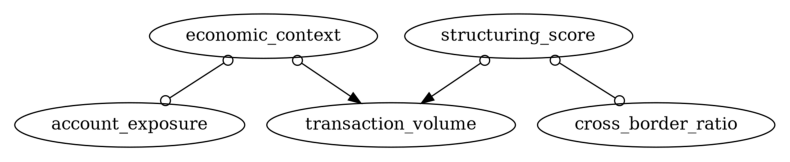

In [40]:
fci_graph = discover_fci(discovery_data, features, alpha=0.05)

pyd = GraphUtils.to_pydot(fci_graph, labels=features)

fp = io.BytesIO(pyd.create_png(f="png"))
img = mpimg.imread(fp, format="png")
plt.figure(figsize=(8, 6))
plt.axis("off")
plt.imshow(img)
plt.show()

### save the causal graph
pyd.write_png("/workspaces/aml-working-paper/reports/figures/fci_causal_graph.png")

### 7. Evaluate relationships

The metrics are the same for both algorithms since:

1. The small amount of observed variables (5) when 10 to 50 nodes are used for better results (https://arxiv.org/html/2404.06349v1)
2. Both algorithms use Fisher-Z and same alpha

Nonetheless, having the same metrics don't mean the same interpretations. FCI helps represent uncertainty about edges' orientations and potential latent confounding. 

In [26]:
pc_metrics = evaluate_skeleton(pc_edges)

In [27]:
pc_metrics

{'TP': 3,
 'FP': 2,
 'FN': 1,
 'precision': 0.6,
 'recall': 0.75,
 'f1': 0.6666666666666665}

In [28]:
fci_metrics = evaluate_skeleton(fci_edges)

In [29]:
fci_metrics

{'TP': 3,
 'FP': 2,
 'FN': 1,
 'precision': 0.6,
 'recall': 0.75,
 'f1': 0.6666666666666665}

### 8. Interpreting the metrics

#### - TP: 3

Three of the relationships found by PC and FCI match the ground truth relationships (('economic_context', 'account_exposure'), ('economic_context', 'transaction_volume') and ('structuring_score', 'transaction_volume'))

#### - FP: 2

PC and FCI found two relationships that are not in the ground truth (structuring_score,cross_border_ratio) and (cross_border_ratio, transaction_volume)

#### - FN: 1

PC and FCI didn't found 1 relationship that is in the ground truth ('account_exposure', 'cross_border_ratio')

#### - Precision: 0.6 (60%)

Out of the instances that the algorithms predicted as positive (matching the ground truth) 60% were actually right. 

#### - Recall: 0.75 (75%)

Put of the actual positive instances, the algorithms managed to find 75% of them. 

#### - F1: 0.67 (67%)

Balancing precision and recall (identifying true relationships vs avoiding false positive relationships) the overall harmonic performance is 67%


### 9. Replicate section 2 -7 for diferent strategies

In [30]:
strategies = ["uncertainty", "surprise", "combined", "random"]

#### For PC

In [31]:
pc_results = []
for strategy in strategies:
    selected = select_investigations(candidates, budget=10, strategy=strategy)
    local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)
    discovery_data = prepare_discovery_data(local_windows)
    pc_graph = discover_pc(discovery_data, features, alpha=0.05)
    pc_edges = []
    for edge in pc_graph.G.get_graph_edges():
        edge_text = str(edge)
        for old_name, new_name in variable_names.items():
            edge_text = edge_text.replace(old_name, new_name)
        pc_edges.append(edge_text)
    metrics = evaluate_skeleton(pc_edges)
    pc_results.append({"Strategy": strategy, "windows": len(local_windows), "accounts": len({w['account_id'] for w in local_windows}), "estimated_edges": pc_edges,  **metrics})

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

In [32]:
pc_strategies = pd.DataFrame(pc_results)
pc_strategies

,Strategy,windows,accounts,estimated_edges,TP,FP,FN,precision,recall,f1
0,uncertainty,10,9,"[economic_context --- account_exposure, econom...",3,2,1,0.60,0.75,0.666667
1,surprise,10,9,"[account_exposure --> economic_context, struct...",3,2,1,0.60,0.75,0.666667
2,combined,10,8,"[account_exposure --> economic_context, transa...",3,1,1,0.75,0.75,0.750000
3,random,10,8,"[economic_context --- account_exposure, econom...",3,1,1,0.75,0.75,0.750000


#### For FCI

In [33]:
fci_results = []
for strategy in strategies:
    selected = select_investigations(candidates, budget=10, strategy=strategy)
    local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)
    discovery_data = prepare_discovery_data(local_windows)
    fci_graph = discover_fci(discovery_data, features, alpha=0.05)
    fci_edges = []
    #print(strategy)
    for edge in fci_graph.get_graph_edges():
        edge_text = str(edge)
        for old_name, new_name in variable_names.items():
            edge_text = edge_text.replace(old_name, new_name)
        #print(edge_text)
        fci_edges.append(edge_text)
    metrics = evaluate_skeleton(fci_edges)
    fci_results.append({"Strategy": strategy, "windows": len(local_windows), "accounts": len({w['account_id'] for w in local_windows}), "estimated_edges": pc_edges,  **metrics})

In [34]:
fci_strategies = pd.DataFrame(fci_results)
fci_strategies

,Strategy,windows,accounts,estimated_edges,TP,FP,FN,precision,recall,f1
0,uncertainty,10,9,"[economic_context --- account_exposure, econom...",3,2,1,0.60,0.75,0.666667
1,surprise,10,9,"[economic_context --- account_exposure, econom...",3,2,1,0.60,0.75,0.666667
2,combined,10,8,"[economic_context --- account_exposure, econom...",3,1,1,0.75,0.75,0.750000
3,random,10,8,"[economic_context --- account_exposure, econom...",3,1,1,0.75,0.75,0.750000


### 10. When incrementing the budget, the better performance for surprise

#### For PC

In [35]:
pc_results_b20 = []
for strategy in strategies:
    selected = select_investigations(candidates, budget=20, strategy=strategy)
    local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)
    discovery_data = prepare_discovery_data(local_windows)
    pc_graph = discover_pc(discovery_data, features, alpha=0.05)
    pc_edges = []
    for edge in pc_graph.G.get_graph_edges():
        edge_text = str(edge)
        for old_name, new_name in variable_names.items():
            edge_text = edge_text.replace(old_name, new_name)
        pc_edges.append(edge_text)
    metrics = evaluate_skeleton(pc_edges)
    pc_results_b20.append({"Strategy": strategy, "windows": len(local_windows), "accounts": len({w['account_id'] for w in local_windows}), "estimated_edges": pc_edges,  **metrics})

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

In [36]:
pc_strategies_w20 = pd.DataFrame(pc_results_b20)
pc_strategies_w20

,Strategy,windows,accounts,estimated_edges,TP,FP,FN,precision,recall,f1
0,uncertainty,20,15,"[economic_context --- account_exposure, econom...",3,2,1,0.600000,0.75,0.666667
1,surprise,20,14,"[account_exposure --> economic_context, struct...",4,2,0,0.666667,1.00,0.800000
2,combined,20,14,"[account_exposure --> economic_context, transa...",3,1,1,0.750000,0.75,0.750000
3,random,20,14,"[economic_context --- account_exposure, econom...",3,1,1,0.750000,0.75,0.750000


#### For FCI

In [37]:
fci_results_b20 = []
for strategy in strategies:
    selected = select_investigations(candidates, budget=20, strategy=strategy)
    local_windows = prepare_local_windows(data=val_df, selected=selected, features=features)
    discovery_data = prepare_discovery_data(local_windows)
    fci_graph = discover_fci(discovery_data, features, alpha=0.05)
    fci_edges = []
    #print(strategy)
    for edge in fci_graph.get_graph_edges():
        edge_text = str(edge)
        for old_name, new_name in variable_names.items():
            edge_text = edge_text.replace(old_name, new_name)
        #print(edge_text)
        fci_edges.append(edge_text)
    metrics = evaluate_skeleton(fci_edges)
    fci_results_b20.append({"Strategy": strategy, "windows": len(local_windows), "accounts": len({w['account_id'] for w in local_windows}), "estimated_edges": pc_edges,  **metrics})

X1 --> X5
X3 --> X5


In [38]:
fci_strategies_w20 = pd.DataFrame(fci_results_b20)
fci_strategies_w20

,Strategy,windows,accounts,estimated_edges,TP,FP,FN,precision,recall,f1
0,uncertainty,20,15,"[economic_context --- account_exposure, econom...",3,2,1,0.600000,0.75,0.666667
1,surprise,20,14,"[economic_context --- account_exposure, econom...",4,2,0,0.666667,1.00,0.800000
2,combined,20,14,"[economic_context --- account_exposure, econom...",3,1,1,0.750000,0.75,0.750000
3,random,20,14,"[economic_context --- account_exposure, econom...",3,1,1,0.750000,0.75,0.750000


#### Until now, under a fixed random seed of 42, surprise-based routing achieved the highest F1 at investigation budgets of 20 and 30 windows with and harmonic performance of 80%. It is capable of finding four of the relationships from the ground truth. Yet, two additional relationships were identified as false positives. This suggests that the surprise routing strategy may help recover the **observable causal diagram** under a limited investigation budget. The best possible performance requires experimentation with multiple random seeds and parameters configurations.

### Other experiments
1. Higher budgets (although higher budgets after 30 don't increase surprise)
2. Different random seeds for different budgets
3. Different values of alpha